In [2]:
import numpy as np
import matplotlib.pyplot as plt


[[1100.   1200.    900.   1000.   1050.  ]
 [ 306.7  2926.     10.     58.74  142.6 ]
 [ 377.8  2720.     12.86   48.84  123.8 ]
 [ 552.7  2964.     29.93   77.22  215.3 ]
 [ 358.4  2948.     12.84   44.95  201.1 ]
 [ 327.7  2719.     11.12   56.42  161.9 ]
 [ 403.3  2712.     33.85   78.34  126.7 ]]
[[ 306.7  2926.     10.     58.74  142.6 ]
 [ 377.8  2720.     12.86   48.84  123.8 ]
 [ 552.7  2964.     29.93   77.22  215.3 ]
 [ 358.4  2948.     12.84   44.95  201.1 ]
 [ 327.7  2719.     11.12   56.42  161.9 ]
 [ 403.3  2712.     33.85   78.34  126.7 ]]
[246.00000000000006, 252.0, 23.85, 33.39, 91.50000000000001]


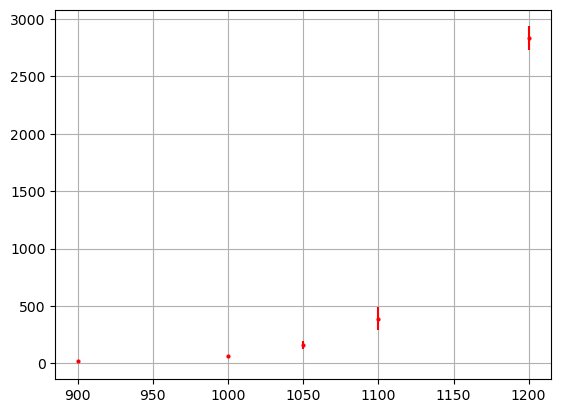

In [24]:
FILE = "Ratebis.txt"

data=np.loadtxt(FILE, unpack=True)
ddp=data[0,:]
r=data[1:,:]

print(data)
print(r)

diffs = [max(colonna) - min(colonna) for colonna in zip(*r)]
sigma=diffs/np.sqrt(6)
print(diffs)
media=sum(r)/len(r)




plt.errorbar(ddp, media , yerr=sigma, fmt="o", markersize=2,color="red")

plt.grid()

plt.show()

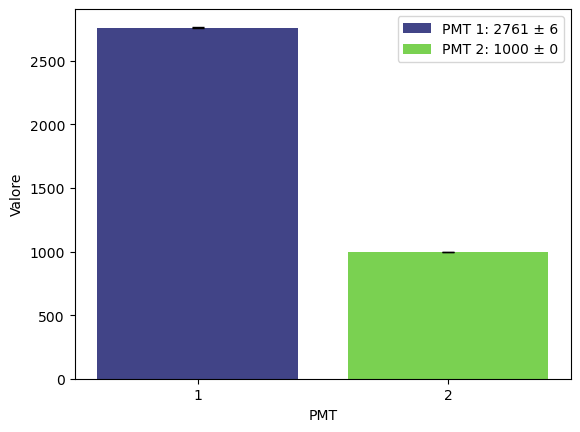

In [63]:
import numpy as np
import matplotlib.pyplot as plt

FILE = "Conteggi scaler.txt"
data = np.loadtxt(FILE, unpack=True)

pmt     = np.asarray(data[0, :]).ravel()
conteggi = data[1:, :]                      # forma (n_eventi, n_pmt)

diffs = np.array([max(col) - min(col) for col in zip(*conteggi)])
sigma = diffs / np.sqrt(len(conteggi))
media = np.mean(conteggi, axis=0)            # media per PMT -> array 1D

colors = plt.cm.viridis(np.linspace(0.2, 0.8, len(pmt)))

fig, ax = plt.subplots()

for i, p in enumerate(pmt):
    ax.bar(
        p, media[i], yerr=sigma[i],
        capsize=4, color=colors[i],
        label=f"PMT {int(p)}: {media[i]:.0f} ± {sigma[i]:.0f}"
    )

ax.set_xticks(pmt)                            # <-- tick sulle posizioni dei PMT
ax.set_xticklabels([str(int(p)) for p in pmt])# <-- etichette intere
ax.set_xlabel("PMT")
ax.set_ylabel("Valore")
ax.legend()

plt.show()

In [ ]:
def Rate_netto(Ns, Nb, ts, tb):
    R=(Ns/ts - Nb/tb)
    sigma=np.sqrt(Ns/ts**2 + Nb/tb**2)
    return R, sigma

def Rate_netto_tempo_morto(R_misurato, taud):
    R_netto = R_misurato / (1 + R_misurato * taud)
    return R_netto

def efficienza(N3,N2):
    eff=N3/N2
    sigma_eff=np.sqrt(eff*(1-eff)/N2)
    return eff, sigma

Sigma della poissoniana è sqrt(N), sigma_rel del Rate è 1/sqrt(N)

In [ ]:
FILE = "conteggi_intervalli.txt"
N = np.loadtxt(FILE, unpack=True)          


media   = N.mean()
varianza = N.var(ddof=1)
print(f"Numero misure : {len(N)}")
print(f"Media         : {media:.3f}")
print(f"Varianza      : {varianza:.3f}")
print(f"Rapporto var/media : {varianza/media:.3f}")



fig, ax = plt.subplots()

bins = np.arange(N.min() - 0.5, N.max() + 0.5, 1 )
ax.hist(N, bins=bins, alpha=0.6, edgecolor="black",
        label="Dati")

k = np.arange(bins[0], bins[-1])
poisson_pmf = stats.poisson.pmf(k, mu=media)
ax.plot(k, poisson_pmf, "o-", color="red", label=f"Poisson(μ={media:.2f})")

ax.set_xlabel("Conteggi per intervallo")
ax.set_ylabel("Densità di probabilità")
ax.set_title("Distribuzione dei conteggi vs Poisson")
ax.legend()
plt.tight_layout()
plt.show()

Stessa cosa ma per i tempo con distribuzione esponenziale

In [ ]:
FILE = "tempi.txt"
t = np.loadtxt(FILE, unpack=True)          

t = np.sort(t)              # assicura ordine crescente
dt = np.diff(t)             # intervalli tra eventi successivi
dt = dt[dt > 0]             # scarta zeri/negativi


tau = dt.mean()

print(f"N. intervalli : {len(dt)}")
print(f"<dt>          : {tau:.4f} s")
print(f"Rate          : {1/tau:.2f} Hz")


fig, ax = plt.subplots()
bins = np.linspace(0, np.max(dt), 40)
ax.hist(dt, bins=bins, density=True, alpha=0.6, edgecolor="black", label="Dati")

x = np.linspace(0, bins[-1], 300)
ax.plot(x, stats.expon.pdf(x, scale=tau), color="red", lw=2,
        label=f"Esponenziale (τ={tau:.3f} s)")

ax.set_xlabel("Δt [s]")
ax.set_ylabel("Densità")
ax.legend()
plt.tight_layout()
plt.show()

